# 14. Object-Oriented Programming

So far in this course we have been following a paradigm known as **Procedural Programming** - as the name suggests, we typically think about the flow of our code as sequential steps and write blocks of code to be executed in sequential order. For every task we need to do, we introduce new variables. If the task is slightly changed, we often need to write a whole new version. These might be fine for short tasks, but for larger projects - think year-long, team-based projects - we often prefer a different coding paradigm that better manages all our variables and functions. 

Here in the last part of our course, we'll introduce **Object-Oriented Programming (OOP)**. In OOP, instead of focusing on the procedural steps of our code, we reorganize the variables and functions we need into data structures known as "objects". For example, if we want to simulate a cat, or maybe more than one cat, we may consider each cat as an object; let's call them cat1 and cat2. When refering to their positions x and velocities v, instead of creating separate variables scattered all over your code like x_cat1, x_cat2, v_cat1, and v_cat2, OOP allows us to write something like cat1.x, cat2.x, cat1.v, cat2.v. Namely, there are only two objects, cat1 and cat2, each with their own variables that can be safely given identical names like x and v, because cat1.x makes it clear that it is the x that belongs to cat1. 

In other words, each object **encapsulates** its own variables that we can refer to in a hierarchical manner, just like organizing files into folders, instead of having all your files lying around at the same level. All these variables that are attached to the object are called its **attributes**, sometimes also known as its **data fields**, or **properties** (often used interchangably). Other attributes that a cat object can have can be e.g. name (a string), weight (a number), breed (a string), etc. 

An object can also possess **methods**, to operate on its data, or execute other tasks like creating a plot. For example, a cat object may have methods like eat() to increases its energy, run() to update its position, or meow() to attract nearby cats. To access these methods (defined in ways that we will discuss later), we would simply write cat1.run(velocity=1) or cat1.eat(calories=100) or cat1.meow(), all using the same dot notation as referring to the cat's data, but with parentheses and appropriate arguments if needed.

The above demonstrates the **Encapsulation** feature of OOP: everything you need to know about the object or need it to perform, whether it is methods or data, can be encapsulated inside the object itself.

If all these dot notations are looking familiar, it would be because **everything we see in python is an object!** 

In [5]:
import numpy as np
import matplotlib.pyplot as plt

#YOUR CODE HERE

Somewhere in the numpy module, the developers have defined these data and methods so that we can make use of them.

Let's try constructing an object on our own next. (Cats are way too complicated for now so let's try simpler objects first!) We'll create and work with two line objects, define these two lines with slopes and intersects, and then plot them. At the end of the day, we would want to write something like

In [ ]:
#YOUR CODE HERE

This doesn't work yet! But it gives you an idea of what data and method we need for each line: c0 and c1 control a line's slope and intersect, and table() serves to make a plot.

You can see that we have created each line object using L.. = Line(..). Here, Line() is a **class** that we need to define. You can think of it as a template or a prototype, where we define all the attributes and methods can our object will need. Then whenever you need to create an object, we can call on this class to create an object as an **instance** of this class, where the objects has all the things readily defined in the class and ready to be put into use.

For example, a Line class may look something like the folloing:

In [26]:
#YOUR CODE HERE

The \_\_init\_\_() internal method is always required. What is "self"? When we are writing this class, this is just a template - you don't know what you're going to call the objects that will be created as instances of this class yet. Even if you have an object name in mind (like L1 or L2), it's going to be different of every object. 

So within the class definition, we refer to this very object that we are focusing on to be self. When writing this class definition, we can imaging that for object L1 that will be created later, self would mean L1; for L2, self would mean L2, etc.

We then also defined an internal method \_\_calc\_\_(), which is encompassed by **double underscores** __ by convention, and an external method table().

Putting everything together now, we have:

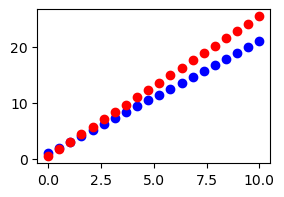

In [29]:
#YOUR CODE HERE

Notice that we have made the code more compact by using an asterisk in front of L1.table() and L2.table() to **unpack** the x and y arrays into the first and second arguments needed for plt.plot.

No more blocks of initializing L1 and L2! We've repackaged everything in a way that contains all the detailed code into the class definition - and when it comes to using L1 and L2, we can construct and operate on them using simple one-liners.

## Inheritance
Next we want to demonstrate another advantage of OOP, **inheritance**. Let's say next you want to create a different class called Parabola. You could start from scratch and write a new block for the Parabola class. But that would go against our principle of "Reuse often"! 

A neater way is to build on top of what we already have in the Line class and **inherit** every attribute and method we have already defined in Line. That way we will only need to introduce into Parabola the new attributes and methods that it needs, without repeating the old ones.

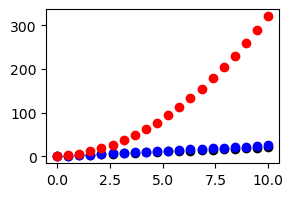

In [12]:
#YOUR CODE HERE

Here we want to introduce another parameter c2 so that the parabola can be described by c0+c1\*x+c2\*x^2. c0 and c1 we took from the Line class, c2 is new.

Notice that the Line inside Parabola(Line) is **not** an argument of a function - it's the **superclass** of Parabola, meaning it's what we base on to write the Parabola class. 

In the Parabola class definition block, we did three things:

For \_\_init\_\_(), we initialized everything we already prepared in the Line class using super() to refer to the Line superclass. This initializes c0 and c1. So all we need to do is initialize c2.

For the \_\_calc\_\_() method, we started from the \_\_calc\_\_() of Line, which already does c0+c1\*x. And we added c2\*x^2.

And for the table() method? We don't need to redefine or update it. It's already perfectly defined in the Line class to create x and y values based on \_\_calc\_\_(). So now our \_\_calc\_\_() is properly updated for Parabola, nothing needs to be done for table().

## Random walk revisited as Objects

Since random walk is fresh in our memory, let's see if we can work with random walk models using objects. The following random walk classes can be downloaded from the Github page of the authors of our textbook:

https://github.com/dr-kinder/code-samples/blob/main/nd_random_walks.py

It's quite long! And it's all class definitions that are supposed to make our lifes easier when working with random walk models. To make use of these classes, let's dissect the first two classes. The rest are just fancier variations of random walk on different lattices and with different step statistics.

## The RandomWalk() class
The minimal, bare-bones class is RandomWalk. It includes some of the very basic parameters we need, some are even placeholders that doesn't have any real content, like the _get_steps() method.

In [2]:
# a snippet copied from nd_random_walks.py.
class RandomWalk():
    def __init__(self, dimension=1):
        # Create a random number generator.
        self.rng = np.random.default_rng()
        # Store dimension and starting point internally.
        self.D = dimension
        self.r0 = np.zeros((self.D,1))

    def _get_steps(self,N):
        # Internal method.  Generate individual steps of the random walk.
        return np.zeros((self.D, N))   # placeholder for parent class
    
    def get_walk(self,N):
        return np.append(self.r0, np.cumsum(self._get_steps(N), axis=1), axis=1)

    def get_endpoints(self,M,N):
        return np.array([self.get_walk(N)[:,-1] for m in range(M)]).transpose()

    def get_distances(self,M,N):
        return np.sqrt(np.sum(self.get_endpoints(M,N)**2, axis=0))

Without scrolling down - let's break into group discussions on what these four methods may be trying to achieve, and what is the shape of array that they return. 

A hint: N is the number RW steps, M is the number of RW particles, D is the dimension of the model, and r0 is the starting point of the RW.

- \_get\_steps() serves to collect all the steps taken. <br>
    **It's D x N in shape**. For example, for a single RW particle in 3D taking 10 steps, the shape would be <br>
. . . . . . . . . .<br>
. . . . . . . . . .<br>
. . . . . . . . . .<br>


- get_walk() serves to collect the trajectory of a particle across all its steps. The cumsum() perserves a D x N shape. The np.append stiches r0 (D x 1) with the cumsum() result (D x N) horizontally along axis=1. Therefore, <br>
    **it's D x (N+1) in shape.**<br>
 . | . . . . . . . . . .<br>
 . | . . . . . . . . . .<br>
 . | . . . . . . . . . .


- get_endpoints() extends the trajectories to M particles and takes everyone's last position using [:,-1], resulting in a M x D array. <br>
    **The final tranpose() then transposes it into a shape of D x M.**
    

- get_distances() converts the x,y,z values in D x M get_endpoints() array into r=sqrt(x^2+y^2+z^2), <br>
    **resulting in a 1 x M array.**
    
Notice that, whenever present, D is always placed in the first dimension (rows), M and N are always placed in the second dimension (columns). This is for better bookkeeping.


## The LatticeWalk() class

The LatticeWalk() class is where we actually setup a concrete random walk particle on the simplest lattices in any dimesion: e.g. a gridline in 1D, a square lattice in 2D, and a cubic lattice in 3D.

In [3]:
class LatticeWalk(RandomWalk):
    def __init__(self, dimension=1):
        super().__init__(dimension)
        # Create list of legal steps on D-dimensional cubic lattice.
        M = np.eye(self.D)
        self.basis = [M[:,n] for n in range(self.D)]
        self.basis += [-M[:,n] for n in range(self.D)]

    def _get_steps(self, N):
        # Generate individual steps by randomly choosing from self.basis.
        return self.rng.choice(self.basis, size=N).transpose()


self.basis provides the steps that the RW particle can take, e.g. for 3D they are (0,0,±1), (0,±1,0), (±1,0,0), arranged into a 6 x 3 array.

Then in \_get\_steps(), the orginal placeholder method in RandomWalk() that is expected to return a D x N array is now updated into an actual method that makes random choices from the basis (steps). It makes N choices, making it N x D, so we do a final transpose() to convert it to D x N as the orginal placeholder had planned. 

It's up to you whether you want to use that final transpose() - you don't have to absolutely always stick to the placeholder's format. But following the placeholder's format of always putting D as the first dimension (as rows) makes bookkeeping simpler here and makes the whole project less prone to errors later on.

Finally, we can play with our model, this time as objects!

The power of LatticeWalk() objects really shines here as we are free to construct RW particles in any dimensions by simply creating RW objects as instances of the LatticeWalk class. Here let's try 1, 2, and 3 dimensions.



In [7]:
#YOUR CODE HERE

(Demonstration: Root-mean-square average of distances is always $\sqrt{\text{Nsteps}}$, regardless of dimensions.)

## Exercise

In this exercise we will plot 

(1) the trajectory of a single 2D RW particle wandering on a square lattice, and 

(2) a scatter plot of multiple RW particle's final positions in 2D. In the scatter plot you should expect to see more dots near the origin, and fewer ones as you go further away from the origin. 

**Find the methods you need in the LatticeWalk class to produce the data you need and plot them.** Some are inherited from the RandomWalk class.

Hint: plt.plot() expects an x array and y array, so you may need to do some array slicing. Recall the shapes of the array returned by the methods(), which we discussed in class. Then slice the arrays along the appropriate axes.